# Activité Pratique N°4 — Architecture Transformer

**Étudiante :** Tawhida AMYAR — EMSI Roudani, 5IDAM  
**Cours :** IA Générative Multi-Modale — Pr. Mohamed YOUSSFI

## Travail demandé
1. Générer une série temporelle `s = sin(x)` (200 valeurs entre 0 et 20) et la ranger en séquences de 10 valeurs → cible = valeur suivante.
2. Modèle **RNN** (16 unités) en PyTorch : créer, entraîner, tester.
3. Modèle **LSTM** (16 unités) : créer, entraîner, tester.
4. Modèle **Transformer** : projection linéaire 1→16, positional embedding, self-attention à 2 têtes (dimension 16), Add & Norm, feed-forward 16→32→16 (ReLU), dernière représentation, Linear 16→1.
5. Exemple de modèle de type **GPT** : prédire la suite d'un texte.
6. Exemple de modèle de type **BERT** : prédire un mot masqué.

Les trois modèles des parties 2 à 4 utilisent exactement les mêmes données, le même optimiseur (Adam, lr = 0,01), la même perte (MSE) et le même nombre d'époques (300) pour pouvoir être comparés.

## 1. Génération du dataset

X_train : (150, 10, 1) | y_train : (150, 1)
X_test  : (40, 10, 1) | y_test  : (40, 1)


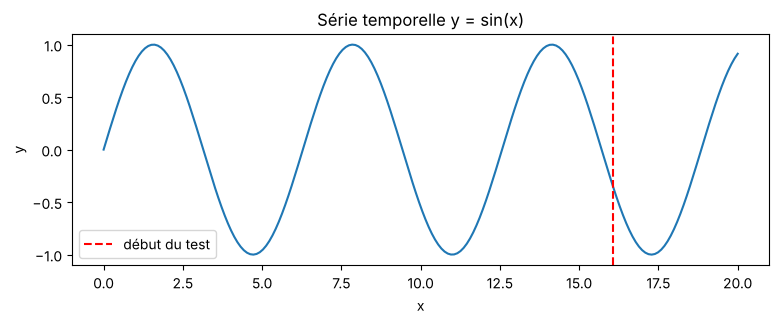

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Série temporelle : s = sin(x), 200 valeurs entre 0 et 20
x = torch.linspace(0, 20, 200)
serie = torch.sin(x)

L = 10  # longueur de chaque séquence

# Fenêtre glissante : X[i] = [s_i ... s_{i+9}]  et  y[i] = s_{i+10}
X = torch.stack([serie[i:i + L] for i in range(len(serie) - L)]).unsqueeze(-1)  # (190, 10, 1)
y = torch.stack([serie[i + L] for i in range(len(serie) - L)]).unsqueeze(-1)    # (190, 1)

# Découpage chronologique : début = apprentissage, fin = test
X_train, y_train = X[:150], y[:150]
X_test,  y_test  = X[150:], y[150:]

print("X_train :", tuple(X_train.shape), "| y_train :", tuple(y_train.shape))
print("X_test  :", tuple(X_test.shape),  "| y_test  :", tuple(y_test.shape))

plt.figure(figsize=(9, 3))
plt.plot(x, serie)
plt.axvline(x[150 + L], color="r", ls="--", label="début du test")
plt.title("Série temporelle y = sin(x)"); plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.show()

## 2. Fonction commune d'entraînement et de test

Chaque modèle est entraîné par rétropropagation (MSE + Adam, 300 époques), puis évalué sur les 40 derniers exemples (jamais vus pendant l'apprentissage).

In [2]:
def entrainer_et_tester(modele, epoques=300, lr=0.01):
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    historique = []

    modele.train()
    for epoch in range(epoques):
        predictions = modele(X_train)
        perte = critere(predictions, y_train)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        historique.append(perte.item())
        if (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

    modele.eval()
    with torch.no_grad():
        pred_test = modele(X_test)
        erreur_test = critere(pred_test, y_test).item()

    nb_params = sum(p.numel() for p in modele.parameters())
    print(f"\nErreur de test (MSE) : {erreur_test:.6f}   | paramètres : {nb_params}")
    print(f"Valeur réelle  : {y_test[0].item():.4f}  | valeur prédite : {pred_test[0].item():.4f}")
    return {"historique": historique, "pred_test": pred_test, "mse_test": erreur_test, "params": nb_params}

resultats = {}

## 3. Modèle RNN

`h_t = tanh(W_ih · x_t + W_hh · h_{t-1} + b)` — 16 unités, état initial h₀ = 0. On garde le **dernier état caché** (B, 16), puis `Linear(16 → 1)`.

In [3]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):                 # x : (B, 10, 1)
        etats, _ = self.rnn(x)            # (B, 10, 16)
        return self.sortie(etats[:, -1])  # dernier état -> (B, 1)

torch.manual_seed(42)
resultats["RNN"] = entrainer_et_tester(SimpleRNN())

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049


Epoch 300 | Erreur : 0.000025

Erreur de test (MSE) : 0.000028   | paramètres : 321
Valeur réelle  : -0.3639  | valeur prédite : -0.3601


## 4. Modèle LSTM

Le LSTM ajoute un **état de cellule** c_t et trois portes (oubli, entrée, sortie) qui contrôlent ce qui est conservé, ajouté ou exposé : la mémoire à long terme est mieux gérée. 16 unités, h₀ = c₀ = 0.

In [4]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.lstm(x)           # (B, 10, 16)
        return self.sortie(etats[:, -1])  # (B, 1)

torch.manual_seed(42)
resultats["LSTM"] = entrainer_et_tester(SimpleLSTM())

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248


Epoch 150 | Erreur : 0.000043


Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004


Epoch 300 | Erreur : 0.000003

Erreur de test (MSE) : 0.000003   | paramètres : 1233
Valeur réelle  : -0.3639  | valeur prédite : -0.3622


## 5. Modèle Transformer (encodeur)

Architecture du tableau :

1. **Projection linéaire** 1 → 16 de chaque valeur ;
2. **Positional embedding** (indices 0 … 9) ajouté aux vecteurs : sans récurrence, c'est lui qui donne l'ordre ;
3. **Multi-Head Self-Attention** (2 têtes, dimension 16) + **Add & Norm** (connexion résiduelle) ;
4. **Feed-Forward** 16 → 32 → 16 avec ReLU + **Add & Norm** ;
5. on garde la **dernière représentation** `[:, -1, :]` ;
6. **Linear** 16 → 1.

Pas de masque causal : les 10 valeurs d'entrée sont toutes connues, chaque position peut regarder toutes les autres.

In [5]:
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10, dimension=16):
        super().__init__()
        self.projection = nn.Linear(1, dimension)               # 1 -> 16
        self.positions = nn.Embedding(longueur_max, dimension)  # positional embedding
        bloc = nn.TransformerEncoderLayer(
            d_model=dimension, nhead=2,        # self-attention à 2 têtes (dimension 8 par tête)
            dim_feedforward=32,                # feed-forward 16 -> 32 -> 16
            dropout=0.0, activation="relu", batch_first=True
        )                                      # contient Add & Norm (résiduels + LayerNorm)
        self.encodeur = nn.TransformerEncoder(bloc, num_layers=1)
        self.sortie = nn.Linear(dimension, 1)                   # 16 -> 1

    def forward(self, x):                      # x : (B, 10, 1)
        indices = torch.arange(x.size(1), device=x.device)
        h = self.projection(x) + self.positions(indices)        # (B, 10, 16)
        h = self.encodeur(h)                                    # (B, 10, 16)
        return self.sortie(h[:, -1, :])                         # dernière représentation -> (B, 1)

torch.manual_seed(42)
resultats["Transformer"] = entrainer_et_tester(MiniTransformer(L))

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110


Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012


Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test (MSE) : 0.000006   | paramètres : 2433
Valeur réelle  : -0.3639  | valeur prédite : -0.3662


## 6. Comparaison des trois modèles

,MSE test,MSE train (fin),Paramètres
RNN,0.000028,0.000025,321
LSTM,0.000003,0.000003,1233
Transformer,0.000006,0.000004,2433


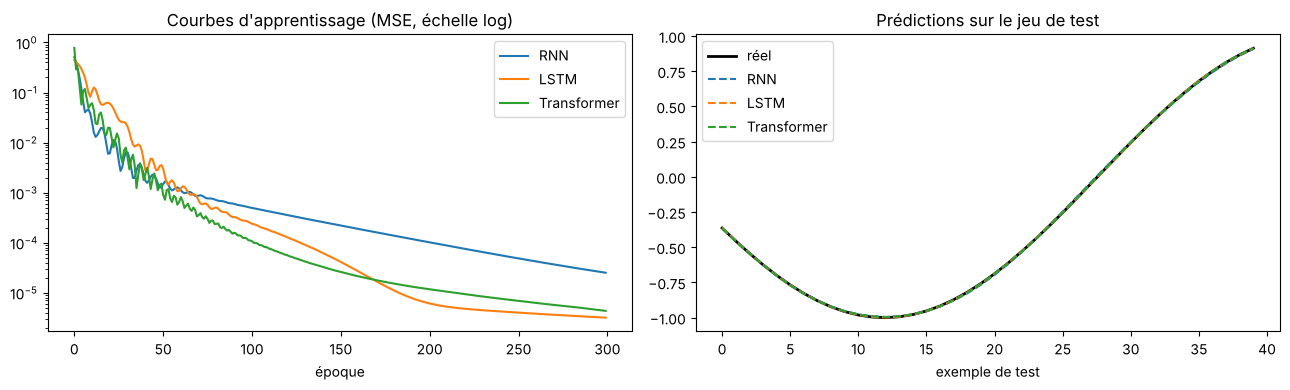

In [6]:
import pandas as pd

tableau = pd.DataFrame({
    "MSE test": {k: v["mse_test"] for k, v in resultats.items()},
    "MSE train (fin)": {k: v["historique"][-1] for k, v in resultats.items()},
    "Paramètres": {k: v["params"] for k, v in resultats.items()},
}).round(6)
display(tableau)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for nom, r in resultats.items():
    axes[0].plot(r["historique"], label=nom)
axes[0].set_yscale("log"); axes[0].set_title("Courbes d'apprentissage (MSE, échelle log)")
axes[0].set_xlabel("époque"); axes[0].legend()

axes[1].plot(y_test.squeeze(), "k", lw=2, label="réel")
for nom, r in resultats.items():
    axes[1].plot(r["pred_test"].squeeze(), "--", label=nom)
axes[1].set_title("Prédictions sur le jeu de test"); axes[1].set_xlabel("exemple de test"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Modèle de type GPT — prédire la suite d'un texte

GPT est un **décodeur Transformer** : il lit le texte de gauche à droite avec un **masque causal** (un token ne voit que les tokens précédents) et prédit le token suivant. On génère en répétant : prédire → ajouter le token → recommencer.

On utilise **GPT-2** préentraîné (Hugging Face) avec l'amorce du tableau : *« Artificial intelligence can … »*.
Prérequis : `pip install transformers` (le modèle est téléchargé au premier lancement, environ 500 Mo).

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("gpt2")
gpt = AutoModelForCausalLM.from_pretrained("gpt2").eval()
tokenizer.pad_token = tokenizer.eos_token

amorce = "Artificial intelligence can help people and organizations"
entrees = tokenizer(amorce, return_tensors="pt")
print("Nombre de tokens de l'amorce :", entrees["input_ids"].shape[1])

torch.manual_seed(42)
with torch.no_grad():
    sortie = gpt.generate(
        **entrees,
        max_new_tokens=40,
        do_sample=True, temperature=0.8, top_p=0.9,   # diversité contrôlée
        pad_token_id=tokenizer.eos_token_id,
    )
print("\nTexte généré :\n", tokenizer.decode(sortie[0], skip_special_tokens=True))

## 8. Modèle de type BERT — prédire un mot masqué

BERT est un **encodeur Transformer bidirectionnel** : chaque token voit les mots à gauche **et** à droite. Pendant le préentraînement, des mots sont remplacés par `[MASK]` et le modèle doit les retrouver. Ici : *« Rabat est la [MASK] du Maroc »* avec `bert-base-multilingual-cased` (le français est supporté).

In [ ]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

tok = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")
bert = AutoModelForMaskedLM.from_pretrained("bert-base-multilingual-cased").eval()

def completer(phrase, k=5):
    entrees = tok(phrase, return_tensors="pt")
    pos = (entrees["input_ids"][0] == tok.mask_token_id).nonzero(as_tuple=True)[0].item()
    with torch.no_grad():
        scores = bert(**entrees).logits[0, pos]
    probas = torch.softmax(scores, dim=-1)
    top_p, top_i = torch.topk(probas, k)
    print(phrase)
    for p, i in zip(top_p, top_i):
        mot = tok.decode([i.item()]).strip()
        print(f"  {p.item():6.2%} | {phrase.replace(tok.mask_token, mot)}")
    print()

completer(f"Rabat est la {tok.mask_token} du Maroc.")
completer(f"{tok.mask_token} est la capitale du Maroc.")

## 9. Conclusion

| Modèle | MSE test | Paramètres |
|---|---|---|
| RNN (16 unités) | ≈ 2,8·10⁻⁵ | 321 |
| LSTM (16 unités) | ≈ 3·10⁻⁶ | 1 233 |
| Transformer (1 bloc, 2 têtes) | ≈ 6·10⁻⁶ | 2 433 |

*(valeurs obtenues avec `torch.manual_seed(42)` ; elles varient légèrement d'une exécution à l'autre.)*

- Les trois modèles prédisent très bien une sinusoïde : c'est un problème simple et très régulier. Les écarts entre eux ne permettent pas de conclure à la supériorité générale d'une architecture.
- **RNN / LSTM** lisent la séquence pas à pas (calcul séquentiel) ; le LSTM, grâce à ses portes, apprend plus vite et mieux que le RNN simple sur cet exemple.
- Le **Transformer** traite les 10 positions en parallèle grâce à l'auto-attention et au positional embedding ; son avantage se voit surtout sur de longues séquences et de grands volumes de données.
- **GPT** (décodeur, masque causal) génère du texte token par token ; **BERT** (encodeur bidirectionnel) comprend le contexte des deux côtés pour retrouver un mot masqué.